This notebook has analyses of the constituent refcats for AIC Refcat.  Essentially, this is not where I'm figuring out code to actually build AIC Refcat, but where I'm figuring out what sources & what info about them from which catalogs to put in there.  

*Use hdps venv*

In [1]:
from astropy import units as astro_unit
import astropy.units as u
import astropy.units.cds as ucds
from astropy.table import *
from dataclasses import dataclass, field
from itertools import combinations
import lsdb
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

#from hdps.catalogs import *

import cocat_column_meta


## ..Re-do catalog data containers

In [ ]:
@dataclass
class ATLASRefcat2_new:
    """Container for ATLAS-Refcat2 catalog & metadata

    Attributes
    ----------
    path (str) Full path to HATSed catalog (location on-disk or URL through data.lsdb.io)
    columns (list[str]) List of column names to load; input for lsdb.open_catalog() (expect elements [0,1,2] to be [ID,RA,Dec] column names)
    filters (list[tuple]) List of filters on rows; input for lsdb.open_catalog()
    catalog (lsdb.Catalog) Lazily-loaded catalog in HATs format; opened with lsdb.open_catalog()
    meta (pandas.DataFrame) meta information for catalog column names and dtypes; input for map_partitions()

    Example:
    --------
    >>> atlas = ATLASRefcat2(path="/path/to/atlas",columns=["id","ra","dec","g"],filters=[["dec",">",-20.0],["g","<",19.0]])
    """

    NAME = "atlas"
    FULL_NAME = "ATLAS-Refcat2"
    DEFAULT_PATH = "/net/scratch/kmfas/atlas_refcat2/atlas_full"

    def __init__(
        self,
        path: str,
        columns: list = None,
        filters: list = None,
        catalog: lsdb.Catalog = None,
        meta: pd.DataFrame = None,
    ):
        self.path = path
        if columns is not None:
            self.columns = columns
        else:
            self.columns = ATLAS_DEFAULT_COLUMNS
        if filters is not None:
            self.filters = filters
        else:
            self.filters = [["g", "<=", 19.0], ["dec", ">=", -20.0]]
        self.catalog = catalog
        self.meta = meta

In [ ]:
@dataclass
class PanSTARRS_new:
    """
    Container for Pan-STARRS catalog & metadata

    Attributes
    ----------
    path (str) Full path to HATSed catalog (location on-disk or URL through data.lsdb.io)
    columns (list[str]) List of column names to load; input for lsdb.open_catalog() (expect elements [0,1,2] to be [ID,RA,Dec] column names)
    filters (list[tuple]) List of filters on rows; input for lsdb.open_catalog()
    catalog (lsdb.Catalog) Lazily-loaded catalog in HATs format; opened with lsdb.open_catalog()
    meta (pandas.DataFrame) meta information for catalog column names and dtypes; input for map_partitions()

    Example:
    --------
    >>> panstarrs = PanSTARRS(path="/path/to/panstarrs",columns=["objid","raMean","decMean","gMeanApMag"],filters=[["decMean",">",-20.0],["gMeanApMag","<",21.0]])

    """

    NAME = "panstarrs"
    FULL_NAME = "Pan-STARRS"
    DEFAULT_PATH = "s3://stpubdata/panstarrs/ps1/public/hats/otmo"

    def __init__(
        self,
        path: str,
        columns: list = None,
        filters: list = None,
        catalog: lsdb.Catalog = None,
        meta: pd.DataFrame = None,
    ):
        self.path = path
        if columns is not None:
            self.columns = columns
        else:

        if filters is not None:
            self.filters = filters
        else:
            self.filters = [
                ["gMeanApMag", ">", 19.0],
                ["gMeanApMag", "<=", 21.0],
                ["decMean", ">=", -20.0],
            ]
        # rename RA,Dec columns for concatenation or xmatching?:
        #if (
        #    (catalog is not None)
        #    and ("raMean" in catalog.columns)
        #    and ("decMean" in catalog.columns)
        #):
        #    catalog = catalog.rename(columns={"raMean": "ra", "decMean": "dec"})
        self.catalog = catalog
        self.meta = meta

<>:38: SyntaxWarning: list indices must be integers or slices, not tuple; perhaps you missed a comma?
<>:38: SyntaxWarning: list indices must be integers or slices, not tuple; perhaps you missed a comma?
/tmp/ipykernel_3066771/3230771423.py:38: SyntaxWarning: list indices must be integers or slices, not tuple; perhaps you missed a comma?
  ["raMean","ra"]                        # (float8, Angle[deg]) Weighted mean of Right Ascension from single epoch detections at epochMean


In [20]:
@dataclass
class GaiaSource_new:
    """
    Container for Gaia DR3 Source catalog & metadata

    Attributes
    ----------
    path (str) Full path to HATSed catalog (location on-disk or URL through data.lsdb.io)
    columns (list[str]) List of column names to load; input for lsdb.open_catalog() (expect elements [0,1,2] to be [ID,RA,Dec] column names)
    filters (list[tuple]) List of filters on rows; input for lsdb.open_catalog()
    catalog (lsdb.Catalog) Lazily-loaded catalog in HATs format; opened with lsdb.open_catalog()
    meta (pandas.DataFrame) meta information for catalog column names and dtypes; input for map_partitions()

    Example:
    --------
    >>> gaiagals = GaiaSource(path="/path/to/gaia",columns=["id","ra","dec","gMag"],filters=[["dec",">",-20],["gMag","<",21]])

    """

    NAME = "gaiasource"
    FULL_NAME = "GaiaSource"
    DEFAULT_PATH = "https://data.lsdb.io/hats/gaia_dr3"

    def __init__(
        self,
        path: str,
        columns: list = None,
        filters: list = None,
        catalog: lsdb.Catalog = None,
        meta: pd.DataFrame = None,
    ):
        self.path = path
        if columns is not None:
            self.columns = columns
        #else:

        if filters is not None:
            self.filters = filters
        else:
            self.filters = [["phot_g_mean_mag",">=","22"],["dec",">=","-20"]]
        self.catalog = catalog
        self.meta = meta


IndentationError: expected an indented block after 'else' statement on line 35 (161388658.py, line 37)

# .Initiate catalog instances

In [2]:
atlas_path = "/net/scratch/kmfas/atlas_refcat2/atlas"
#atlas = ATLASRefcat2(path=atlas_path)
ps1_path = "/net/scratch/kmfas/panstarrs"
#panstarrs = PanSTARRS(path=ps1_path,filters=[])
gaia_path = "/net/scratch/kmfas/gaia"
#gaia = GaiaSource(path=gaia_path)

In [3]:
# Cone Search
cone_cen_ra = 40 # degree
cone_cen_dec = 30 # degree
cone_rad = 0.5 # degree

# Open a cone of PanSTARRS:
ps1_path = "/net/scratch/kmfas/panstarrs"
panstarrs_cone = lsdb.open_catalog(ps1_path,
                                   columns=["objID","epochMean","raMean","decMean","pmra","pmdec","gMeanApMag","gMeanPSFMag","rMeanApMag","iMeanApMag","qualityFlag","objInfoFlag","nDetections"],
                                   filters=[["gMeanApMag", "<=", 19.0],["rMeanApMag","<=",19.0],["iMeanApMag","<=",19.0]],#,["decMean", ">=", -20.0]]
                                   search_filter=lsdb.ConeSearch(ra=cone_cen_ra, dec=cone_cen_dec, radius_arcsec=(3600*cone_rad)))

# Open a cone of Gaia to perform the xmatch against.
# Gaia DR3 is a catalog collection; opening the collection’s URL 
# automatically loads an appropriate margin cache. 
gaia_path = "/net/scratch/kmfas/gaia"
gaia_cone = lsdb.open_catalog(gaia_path,
                         columns=["source_id","ref_epoch","ra", "dec", "phot_g_n_obs", "phot_g_mean_mag", "pm","rv_time_duration"],
                         filters=[["phot_g_mean_mag","<=",22]],
                         search_filter=lsdb.ConeSearch(ra=cone_cen_ra, dec=cone_cen_dec, radius_arcsec=(3600*cone_rad)))

# Plan the xmatch between the filtered PS and Gaia,  
# using an xmatch radius = 3'' and 1 neighbor to find within each point
xmatch_rad = 3 # degree
ps_x_gaia_cone = panstarrs_cone.crossmatch(gaia_cone,
                            n_neighbors=1,
                            radius_arcsec=xmatch_rad)

/home/kmfas/hdps/.venv/lib/python3.14/site-packages/lsdb/catalog/catalog.py:358: FutureWarning: The default suffix behavior will change from applying suffixes to all columns to only applying suffixes to overlapping columns in a future release.To maintain the current behavior, explicitly set `suffix_method='all_columns'`. To change to the new behavior, set `suffix_method='overlapping_columns'`.
  warnings.warn(


In [4]:
panstarrs_cone_dat = panstarrs_cone.compute()
gaia_cone_dat = gaia_cone.compute()
ps_x_gaia_cone_dat = ps_x_gaia_cone.compute()
print(len(panstarrs_cone_dat),len(gaia_cone_dat),len(ps_x_gaia_cone_dat))

Computing Catalog:   0%|          | 0/13 [00:00<?, ?it/s]

Computing Catalog:   0%|          | 0/4 [00:00<?, ?it/s]

Computing Catalog:   0%|          | 0/18 [00:00<?, ?it/s]

93757 5069 3736


In [5]:
print(f"{100*len(panstarrs_cone_dat.dropna(subset=["pmra"]))/len(panstarrs_cone_dat):.2f}% of PS sources have proper motion within this cone search")

1.96% of PS sources have proper motion within this cone search


In [53]:
mask = (ps_cone_dframe['pmra']!=np.unique(ps_cone_dframe['pmra'])[-1]).fillna(False).values
mask

<ArrowExtensionArray>
[False, False, False, False, False, False, False, False, False, False,
 ...
 False, False, False, False, False, False, False, False, False, False]
Length: 212263, dtype: bool[pyarrow]

In [61]:
ps_cone_dframe = panstarrs_cone_dat.explode("pmra")
ps_cone_dframe[ps_cone_dframe['pmra']==(np.unique(ps_cone_dframe['pmra'])[-1])]
#(np.unique(panstarrs_cone_dat['pmra'])[-1])


,objID,raMean,decMean,pmra,pmdec,gMeanApMag,gMeanPSFMag,rMeanApMag,iMeanApMag,zMeanApMag,yMeanApMag,qualityFlag,objInfoFlag,nDetections
_healpix_29,,,,,,,,,,,,,,


## ..Investingating PanSTARRS qualityFlag and objInfoFlag values in an attempt to clean up data

In [180]:
def decompose_to_values(n):
    powers = []
    i = 1
    while i <= n:
        if i & n:
            powers.append(i)
        i <<= 1
    return powers

[(i,decompose_to_values(i),sum(decompose_to_values(i))) for i in np.unique(panstarrs_cone_dat['qualityFlag'])] # prints (bit flag, [flags])
#[i for i in ps if ((64 in decompose_to_values(i)) or (128 in decompose_to_values(i)))]

[(np.int16(16), [16], 16),
 (np.int16(17), [1, 16], 17),
 (np.int16(20), [4, 16], 20),
 (np.int16(21), [1, 4, 16], 21),
 (np.int16(32), [32], 32),
 (np.int16(33), [1, 32], 33),
 (np.int16(36), [4, 32], 36),
 (np.int16(37), [1, 4, 32], 37),
 (np.int16(39), [1, 2, 4, 32], 39),
 (np.int16(40), [8, 32], 40),
 (np.int16(44), [4, 8, 32], 44),
 (np.int16(45), [1, 4, 8, 32], 45),
 (np.int16(48), [16, 32], 48),
 (np.int16(49), [1, 16, 32], 49),
 (np.int16(52), [4, 16, 32], 52),
 (np.int16(53), [1, 4, 16, 32], 53),
 (np.int16(55), [1, 2, 4, 16, 32], 55),
 (np.int16(60), [4, 8, 16, 32], 60),
 (np.int16(61), [1, 4, 8, 16, 32], 61),
 (np.int16(62), [2, 4, 8, 16, 32], 62),
 (np.int16(63), [1, 2, 4, 8, 16, 32], 63),
 (np.int16(64), [64], 64),
 (np.int16(76), [4, 8, 64], 76),
 (np.int16(96), [32, 64], 96),
 (np.int16(97), [1, 32, 64], 97),
 (np.int16(100), [4, 32, 64], 100),
 (np.int16(101), [1, 4, 32, 64], 101),
 (np.int16(104), [8, 32, 64], 104),
 (np.int16(108), [4, 8, 32, 64], 108),
 (np.int16(117

In [ ]:
# get every bitflag that is a combination of any number of the good qualityFlag values:
good_qualityFlags = [1,2,4,8,16,32]
good_qualityBitflags = [
    sum(combo)
    for r in range(len(good_qualityFlags) + 1) 
    for combo in combinations(good_qualityFlags, r)
]
np.sort(good_qualityBitflags)

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50,
       51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63])

# .Cleaning up PanSTARRS
trying out the qualityFlag and objInfoFlag columns.  Descriptions of flags are __[here](https://outerspace.stsci.edu/spaces/PANSTARRS/pages/298812464/PS1+Object+Flags)__ 

**Flags to try removing:**

- qualityFlag: (removing both 64 & 128 means all bitflags of value < 64 are good to keep)
    - [64] suspect stack object (no more than 1 good measurement, 2 or more suspect or good stack measurement)
    - [128] poor-quality stack object (no more than 1 good or suspect measurement)
- objInfoFlag:
    - [512?] at least one detection identified with a known solar-system object (asteroid or other) (does basically nothing)
    - [1024] most detections identified with a known solar-system object (asteroid or other) (also does basically nothing)

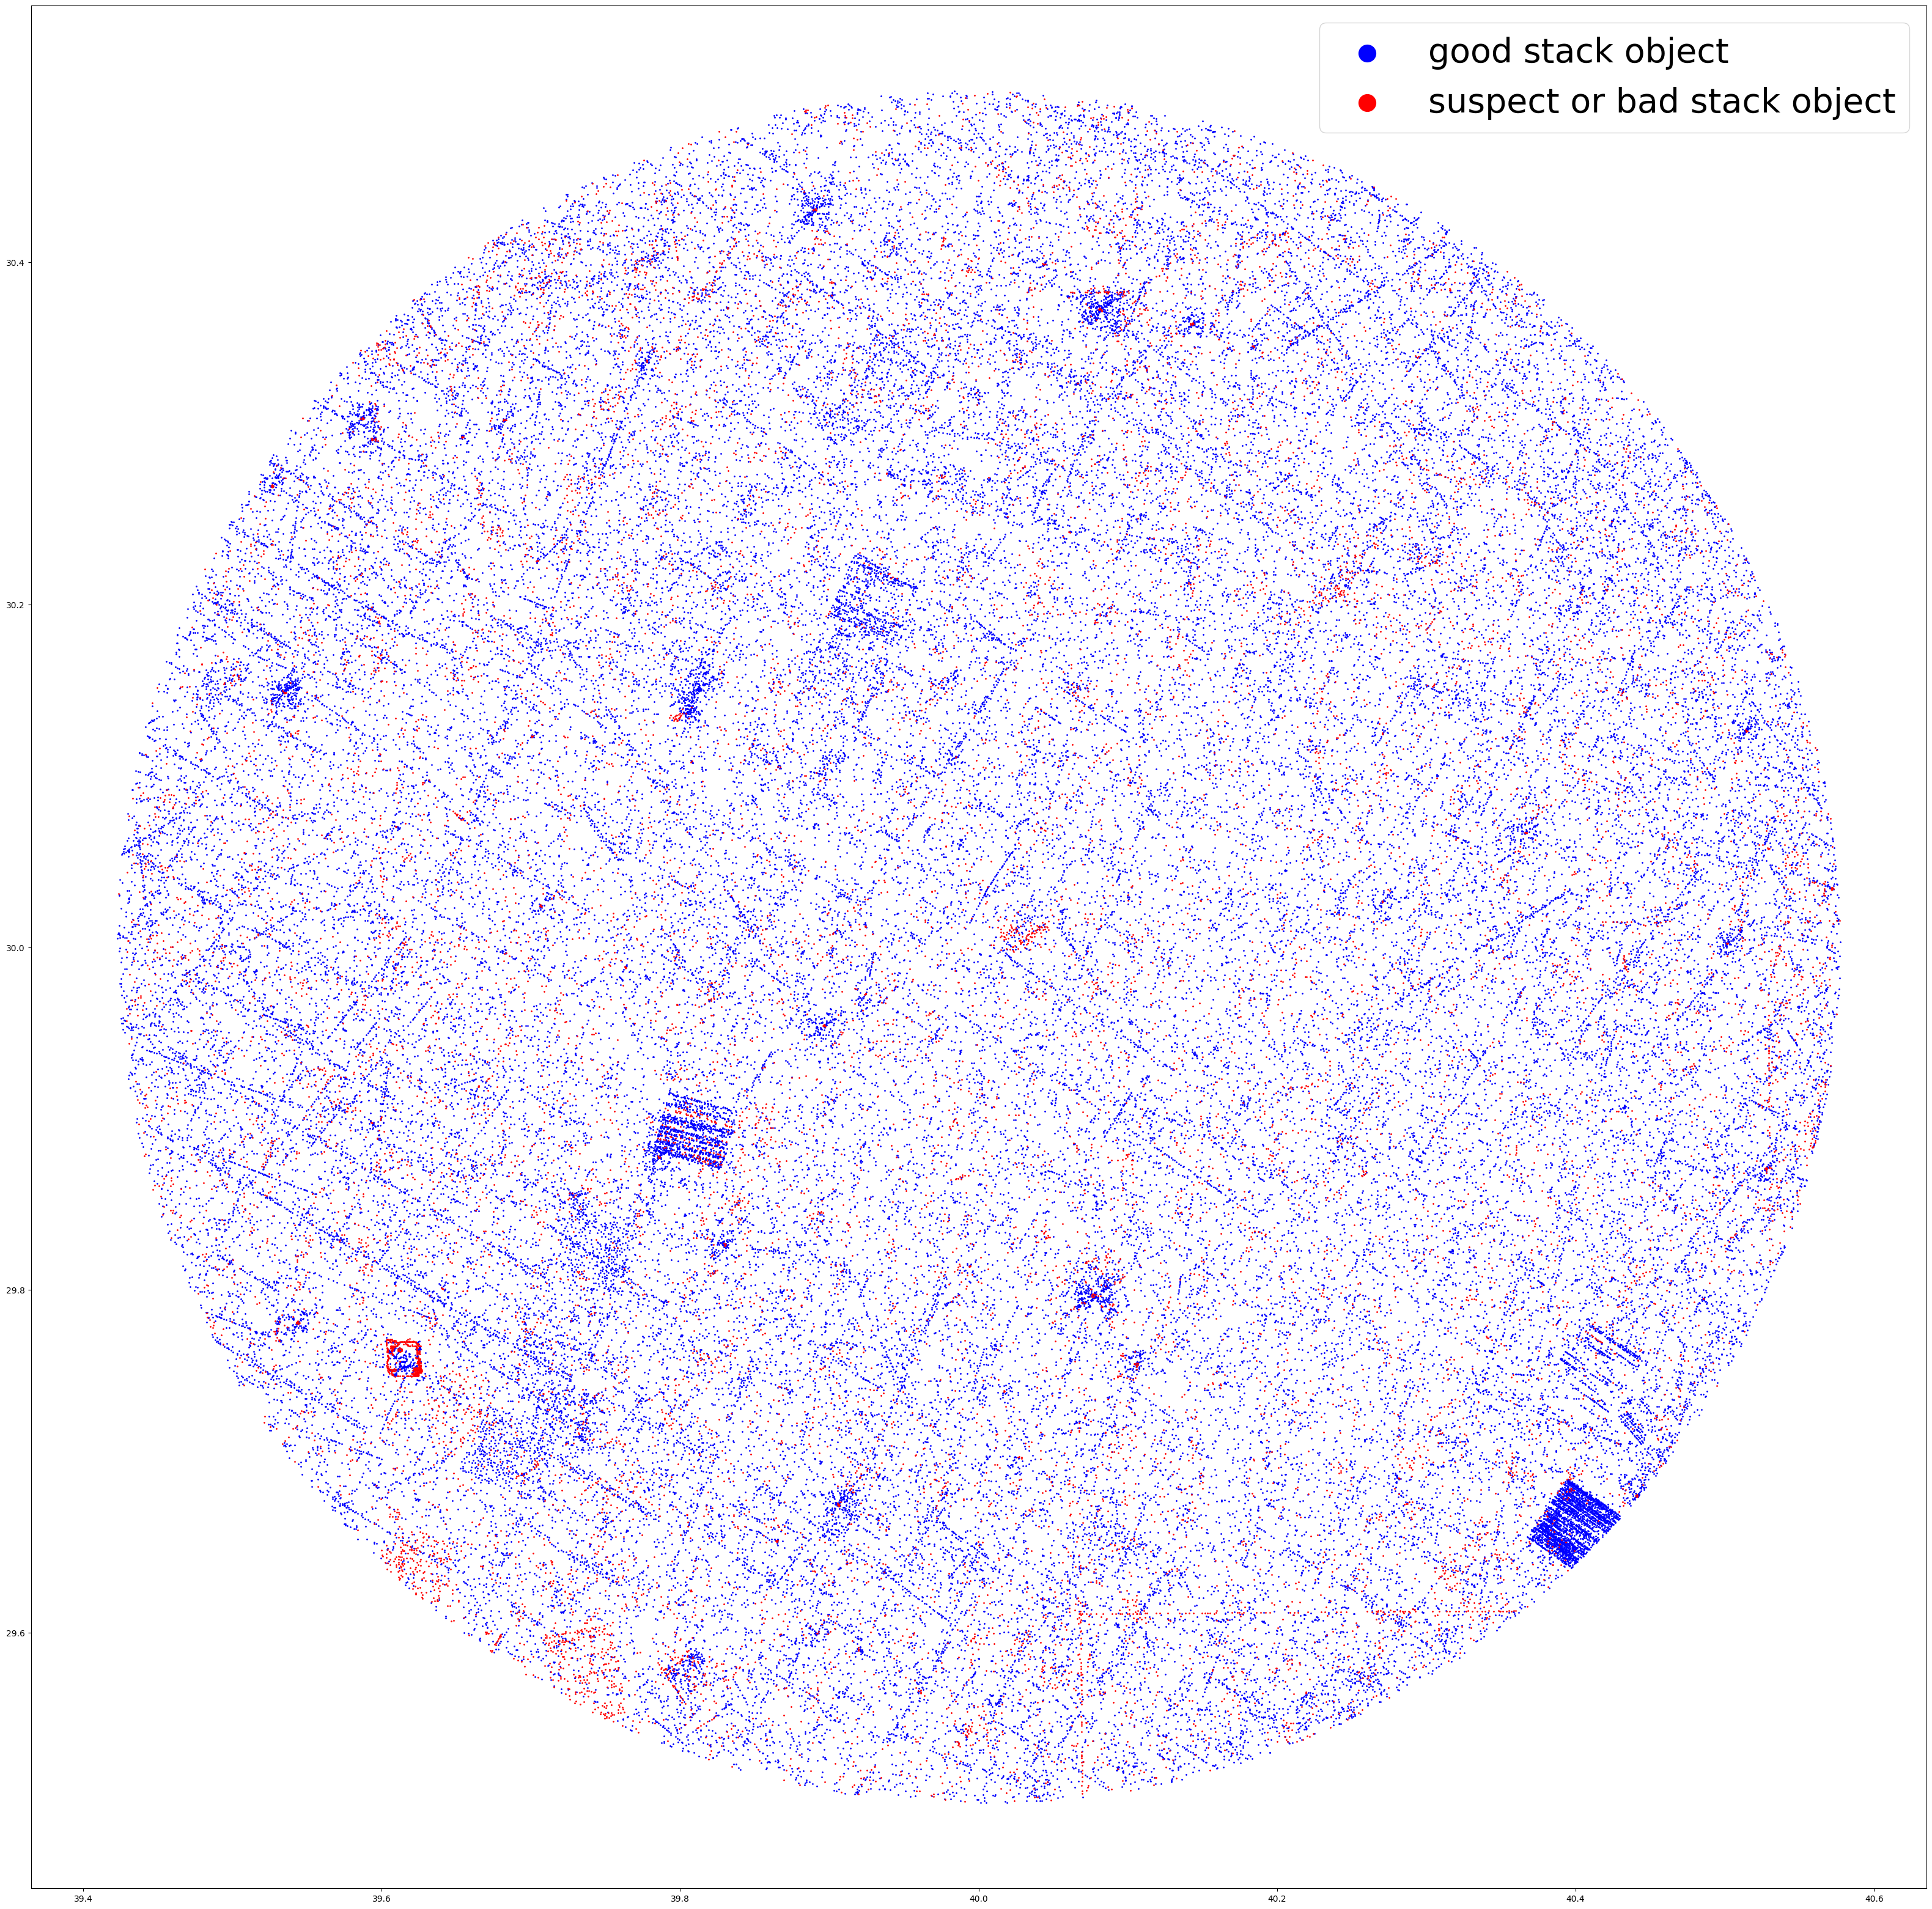

In [7]:
plt.figure(figsize=(40,40))
plt.scatter(panstarrs_cone_dat[panstarrs_cone_dat['qualityFlag']<64]['raMean'],panstarrs_cone_dat[panstarrs_cone_dat['qualityFlag']<64]['decMean'],s=1,c="blue",label="good stack object")
plt.scatter(panstarrs_cone_dat[panstarrs_cone_dat['qualityFlag']>63]['raMean'],panstarrs_cone_dat[panstarrs_cone_dat['qualityFlag']>63]['decMean'],s=1,c="red",label="suspect or bad stack object")
plt.legend(fontsize=40,markerscale=20)
plt.show()

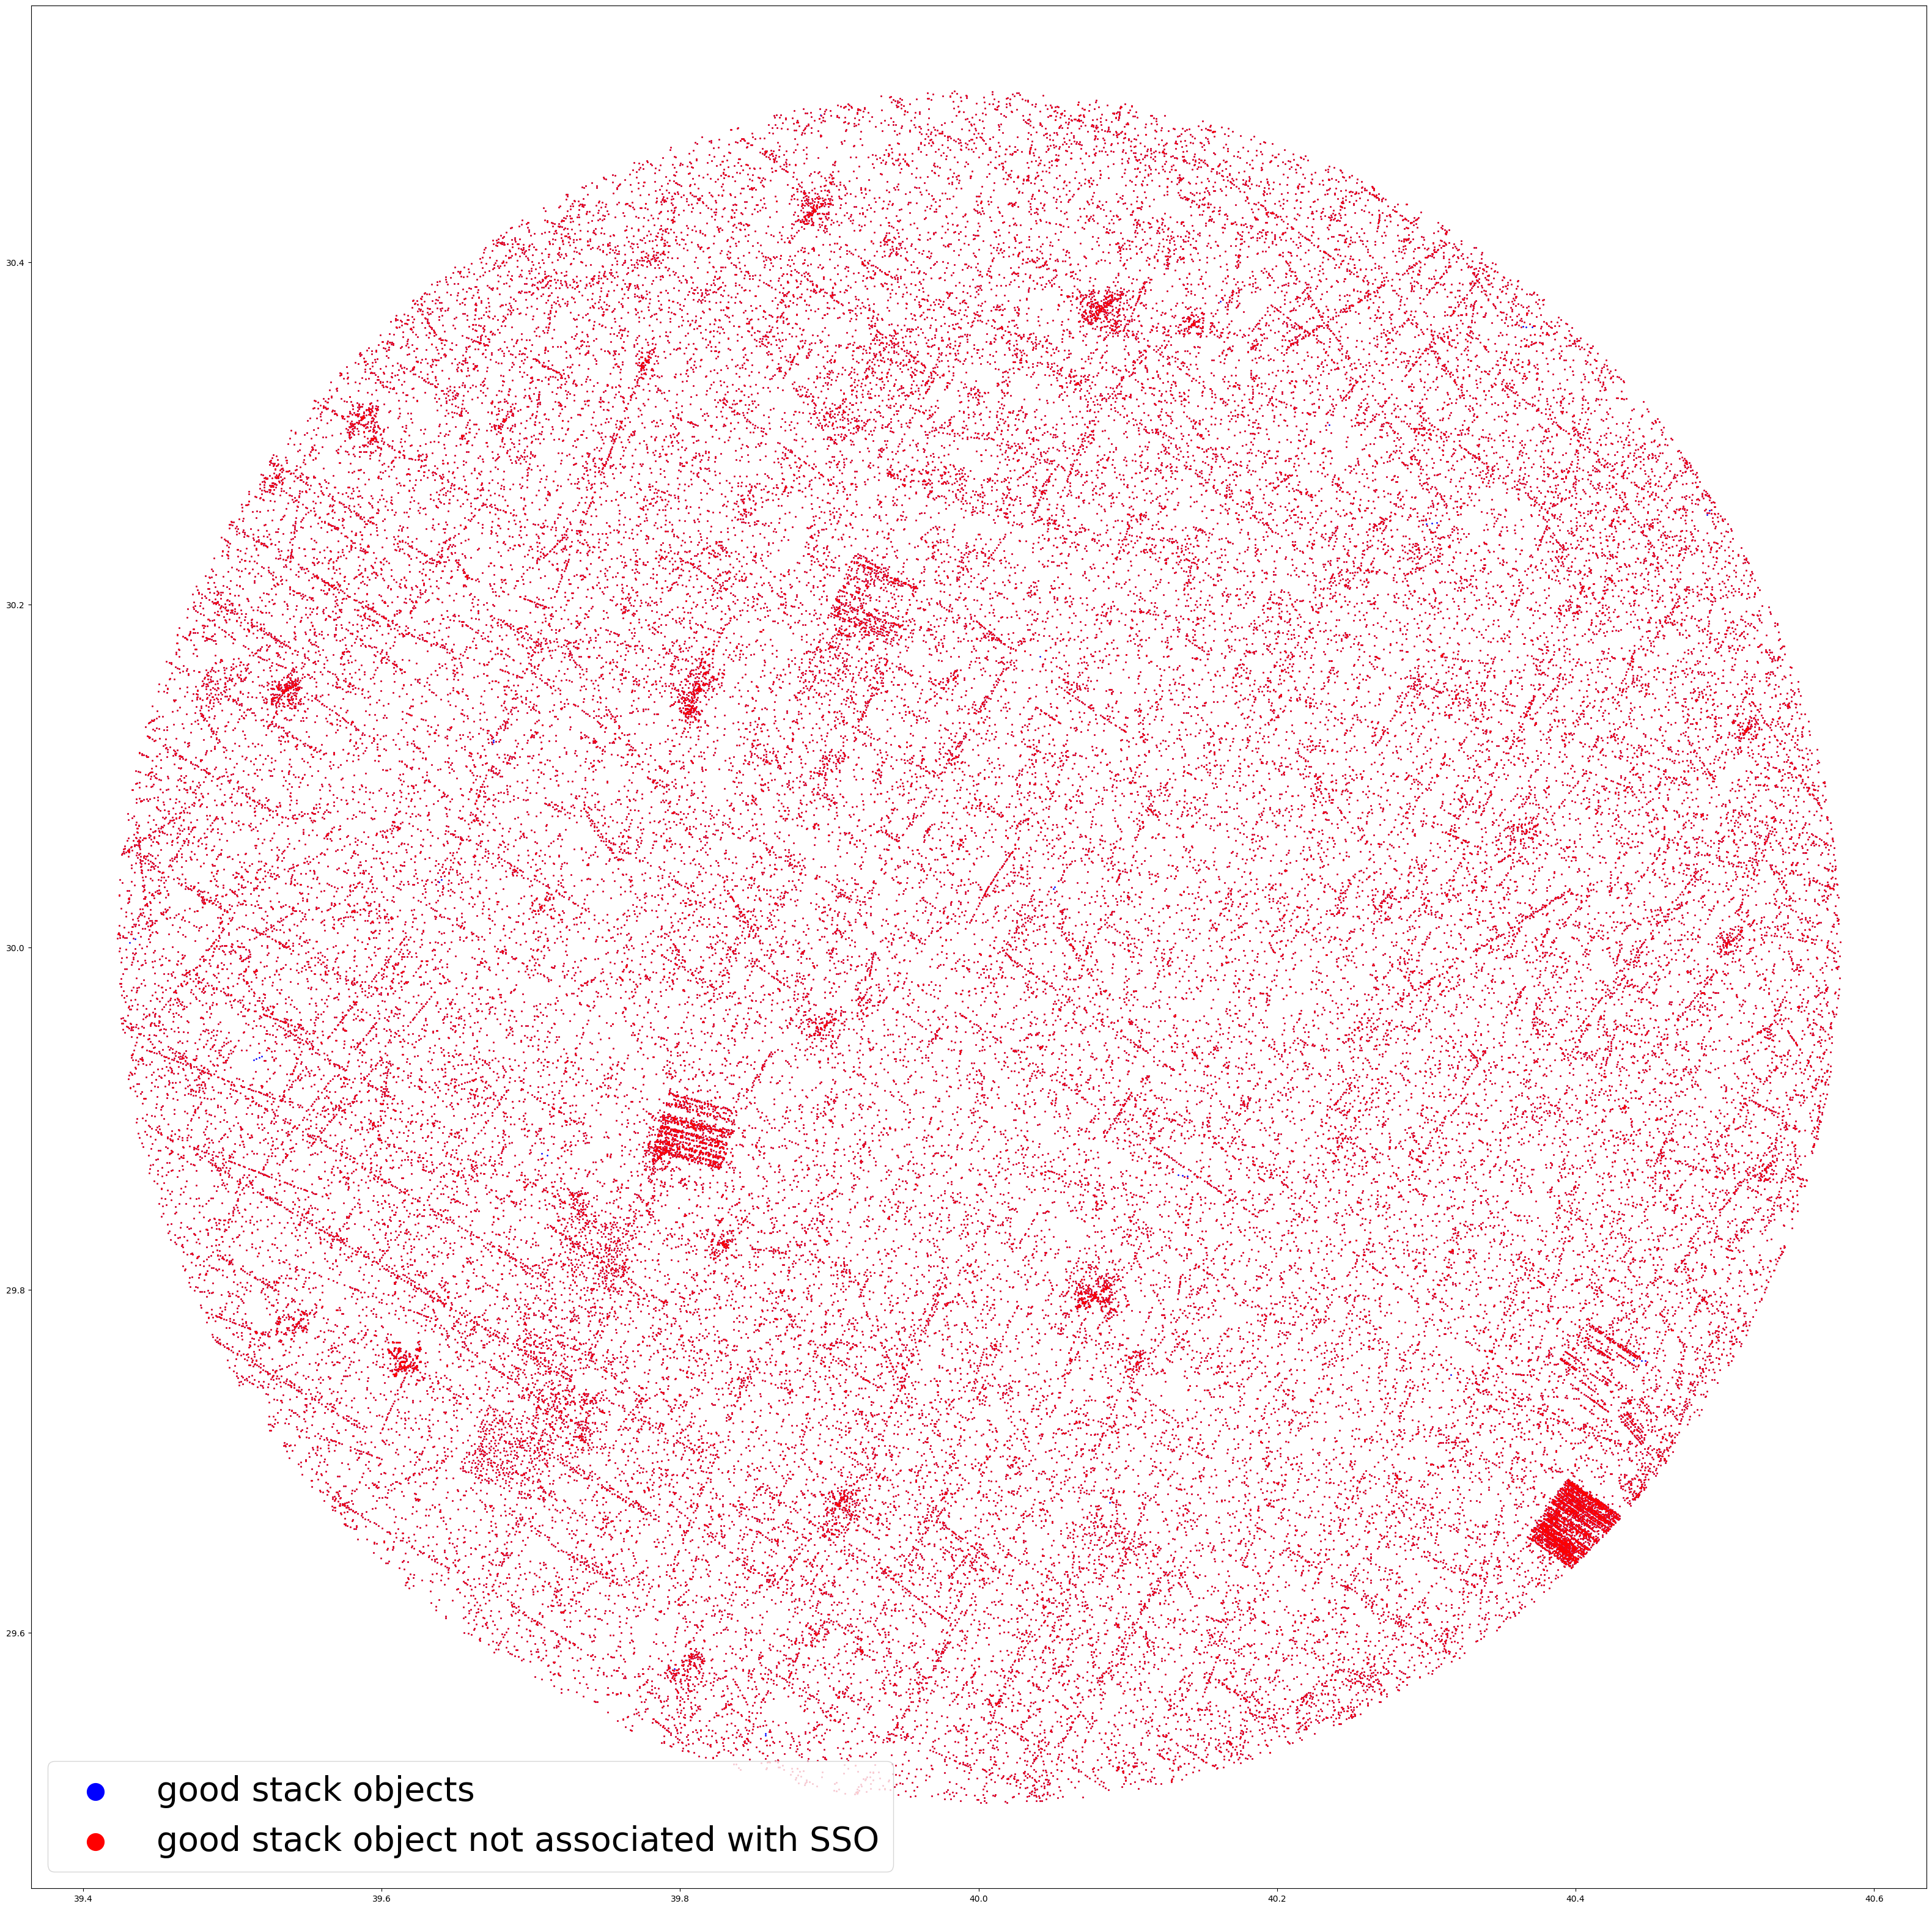

In [8]:
# select only objects that are good in the stack and either (1) [1024] are not mostly comprised of detections identified with a known SSO or (b) [512] don't have at least 1 detection identified with a known SSO
good_and_not_ssos = (panstarrs_cone_dat['qualityFlag']<64) & ~((512 & panstarrs_cone_dat['objInfoFlag']).astype(bool))

plt.figure(figsize=(40,40))
plt.scatter(panstarrs_cone_dat[panstarrs_cone_dat['qualityFlag']<64]['raMean'],panstarrs_cone_dat[panstarrs_cone_dat['qualityFlag']<64]['decMean'],s=1,c="blue",label="good stack objects")
plt.scatter(panstarrs_cone_dat[good_and_not_ssos]['raMean'],panstarrs_cone_dat[good_and_not_ssos]['decMean'],s=1,c="red",label="good stack object not associated with SSO")
plt.legend(fontsize=40,markerscale=20)
plt.show()


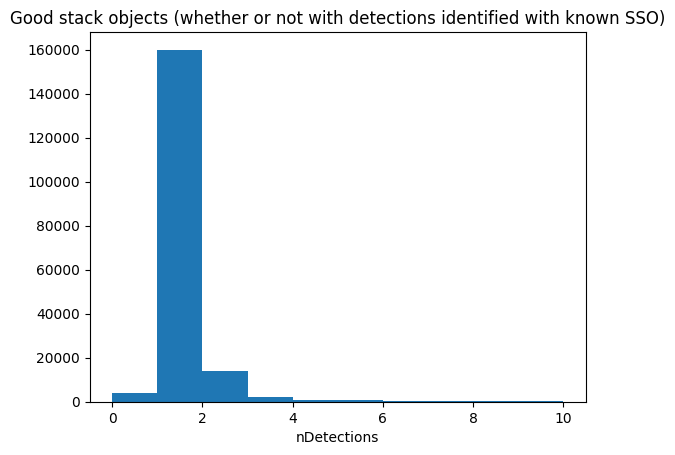

In [189]:
plt.title("Good stack objects (whether or not with detections identified with known SSO)")
plt.hist(panstarrs_cone_dat[panstarrs_cone_dat['qualityFlag']<64]['nDetections'],bins=10,range=[0,10])#=max(panstarrs_cone_dat[panstarrs_cone_dat['qualityFlag']<64]['nDetections']))
plt.xlabel("nDetections")
plt.show()

In [199]:
decompose_to_values(48)

[16, 32]

In [198]:
good_and_no_dets = (panstarrs_cone_dat['qualityFlag']<64) & (panstarrs_cone_dat['nDetections']==0)
panstarrs_cone_dat[good_and_no_dets]


,objID,raMean,decMean,gMeanApMag,qualityFlag,objInfoFlag,nDetections
_healpix_29,,,,,,,
64138737475911583,143430398453648655,39.845309,29.531717,-999.0,48,404226048,0
64138761049901258,143440398424151056,39.842442,29.533763,-999.0,48,404226048,0
...,...,...,...,...,...,...,...
66446874238707288,144560398503776987,39.85022,30.47195,-999.0,48,404226048,0
66447062173376132,144570398615244463,39.861524,30.478239,-999.0,48,404226048,0


In [206]:
panstarrs_cone_dat

,decMean,decMeanErr,epochMean,gFlags,gMeanPSFMag,gMeanPSFMagErr,iFlags,iMeanPSFMag,iMeanPSFMagErr,nDetections,ng,ni,nr,ny,nz,objID,objInfoFlag,qualityFlag,raMean,raMeanErr,rFlags,rMeanPSFMag,rMeanPSFMagErr,surveyID,yFlags,yMeanPSFMag,yMeanPSFMagErr,zFlags,zMeanPSFMag,zMeanPSFMagErr
_healpix_29,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
64138325009434516,29.513284,0.29287,56219.408021,0,-999.0,-999.0,4120,22.0056,0.292489,1,0,1,0,0,0,143410398715226504,268959744,32,39.871555,0.29287,0,-999.0,-999.0,0,0,-999.0,-999.0,0,-999.0,-999.0
64138326551803569,29.513952,0.001,55990.12765,16416,-999.0,-999.0,114720,-999.0,-999.0,0,0,0,0,0,0,143410398695897318,1343750144,160,39.869589,0.001,16416,-999.0,-999.0,0,16416,-999.0,-999.0,16416,-999.0,-999.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66447070753399149,30.483444,0.04094,55482.762234,16416,-999.0,-999.0,16794160,21.274,0.101058,3,0,1,2,0,0,144580398556010682,1384198144,165,39.855562,0.04094,16892472,21.007299,0.096142,0,16416,-999.0,-999.0,16416,-999.0,-999.0
66447070762831199,30.483613,0.08226,55482.426632,0,-999.0,-999.0,0,-999.0,-999.0,1,0,0,1,0,0,144580398558960920,310456320,37,39.855912,0.08226,16777752,21.3174,0.080879,0,0,-999.0,-999.0,0,-999.0,-999.0


In [ ]:
# how many objects have at least one <filter> ap mag value? and why is it not all?
len(panstarrs_cone_dat[(panstarrs_cone_dat["gMeanApMag"]!=-999.0) | (panstarrs_cone_dat["rMeanApMag"]!=-999.0) | (panstarrs_cone_dat["iMeanApMag"]!=-999.0) | (panstarrs_cone_dat["zMeanApMag"]!=-999.0) | (panstarrs_cone_dat["yMeanApMag"]!=-999.0)])/len(panstarrs_cone_dat)

0.8308749051883748

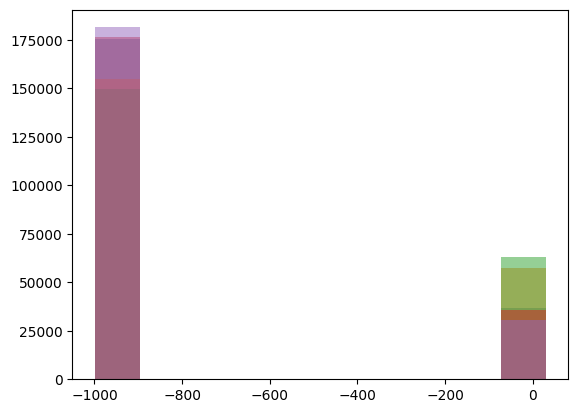

In [214]:
plt.hist(panstarrs_cone_dat['gMeanApMag'],alpha=0.5)
#plt.hist(panstarrs_cone_dat['gMeanPSFMag'],alpha=0.5)
plt.hist(panstarrs_cone_dat['rMeanApMag'],alpha=0.5)
plt.hist(panstarrs_cone_dat['iMeanApMag'],alpha=0.5)
plt.hist(panstarrs_cone_dat['zMeanApMag'],alpha=0.5)
plt.hist(panstarrs_cone_dat['yMeanApMag'],alpha=0.5)
plt.show()

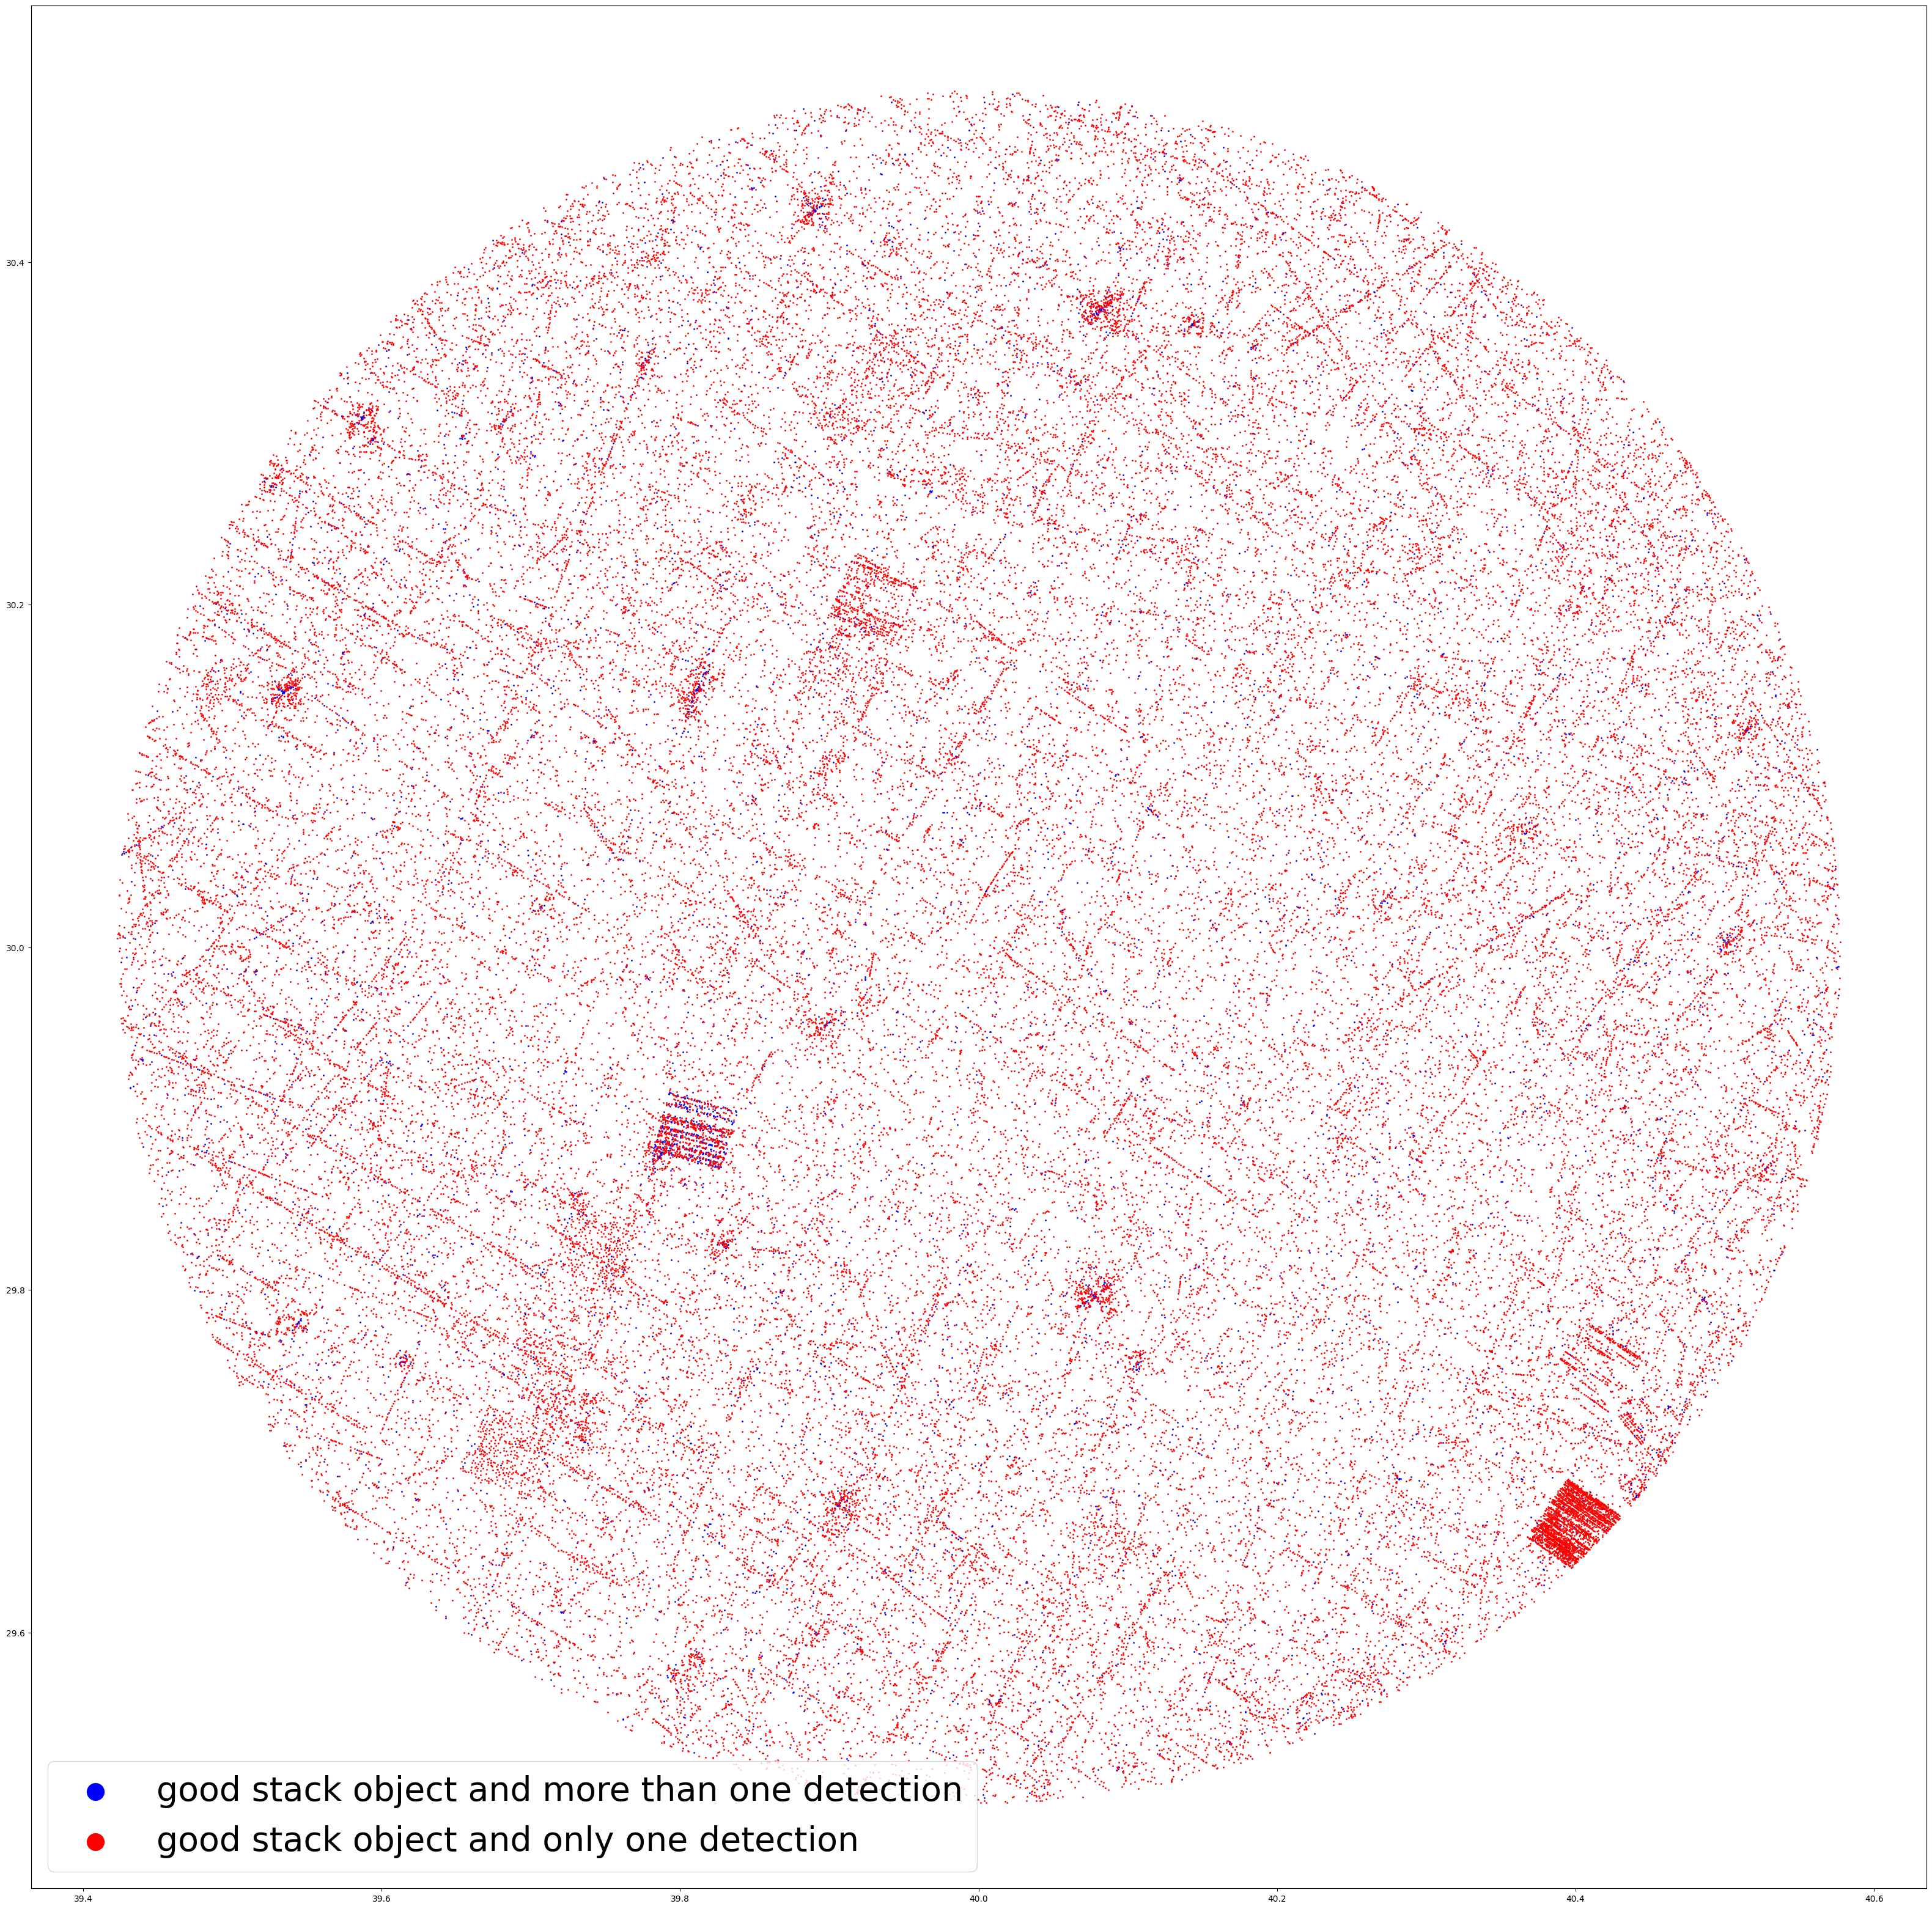

In [9]:
good_and_one_det = (panstarrs_cone_dat['qualityFlag']<64) & (panstarrs_cone_dat['nDetections']==1)

good_and_more_than_one_det = (panstarrs_cone_dat['qualityFlag']<64) & (panstarrs_cone_dat['nDetections']>1)

plt.figure(figsize=(40,40))
plt.scatter(panstarrs_cone_dat[good_and_more_than_one_det]['raMean'],panstarrs_cone_dat[good_and_more_than_one_det]['decMean'],s=1,c="blue",label="good stack object and more than one detection")
plt.scatter(panstarrs_cone_dat[good_and_one_det]['raMean'],panstarrs_cone_dat[good_and_one_det]['decMean'],s=1,c="red",label="good stack object and only one detection")
plt.legend(fontsize=40,markerscale=20)
plt.show()

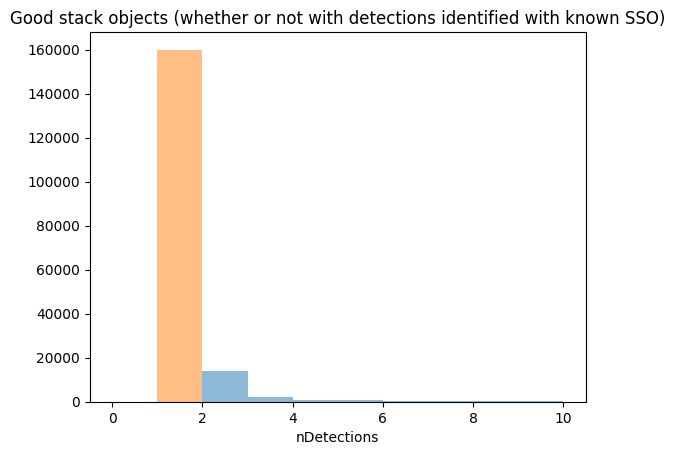

In [196]:
plt.title("Good stack objects (whether or not with detections identified with known SSO)")
plt.hist(panstarrs_cone_dat[good_and_more_than_one_det]['nDetections'],bins=10,range=[0,10],alpha=0.5)
plt.hist(panstarrs_cone_dat[good_and_one_det]['nDetections'],bins=10,range=[0,10],alpha=0.5)
plt.xlabel("nDetections")
plt.show()

In [ ]:
# try out filtering PS in quality flag:
ps_test = lsdb.open_catalog(ps1_path,filters=[["qualityFlag","in",[16,17,32]]],search_filter=lsdb.ConeSearch(ra=cone_cen_ra, dec=cone_cen_dec, radius_arcsec=(3600*cone_rad)))

In [102]:
ps_test_dat = ps_test.compute()

Computing Catalog:   0%|          | 0/13 [00:00<?, ?it/s]

In [135]:
bool(63 & 1)

True

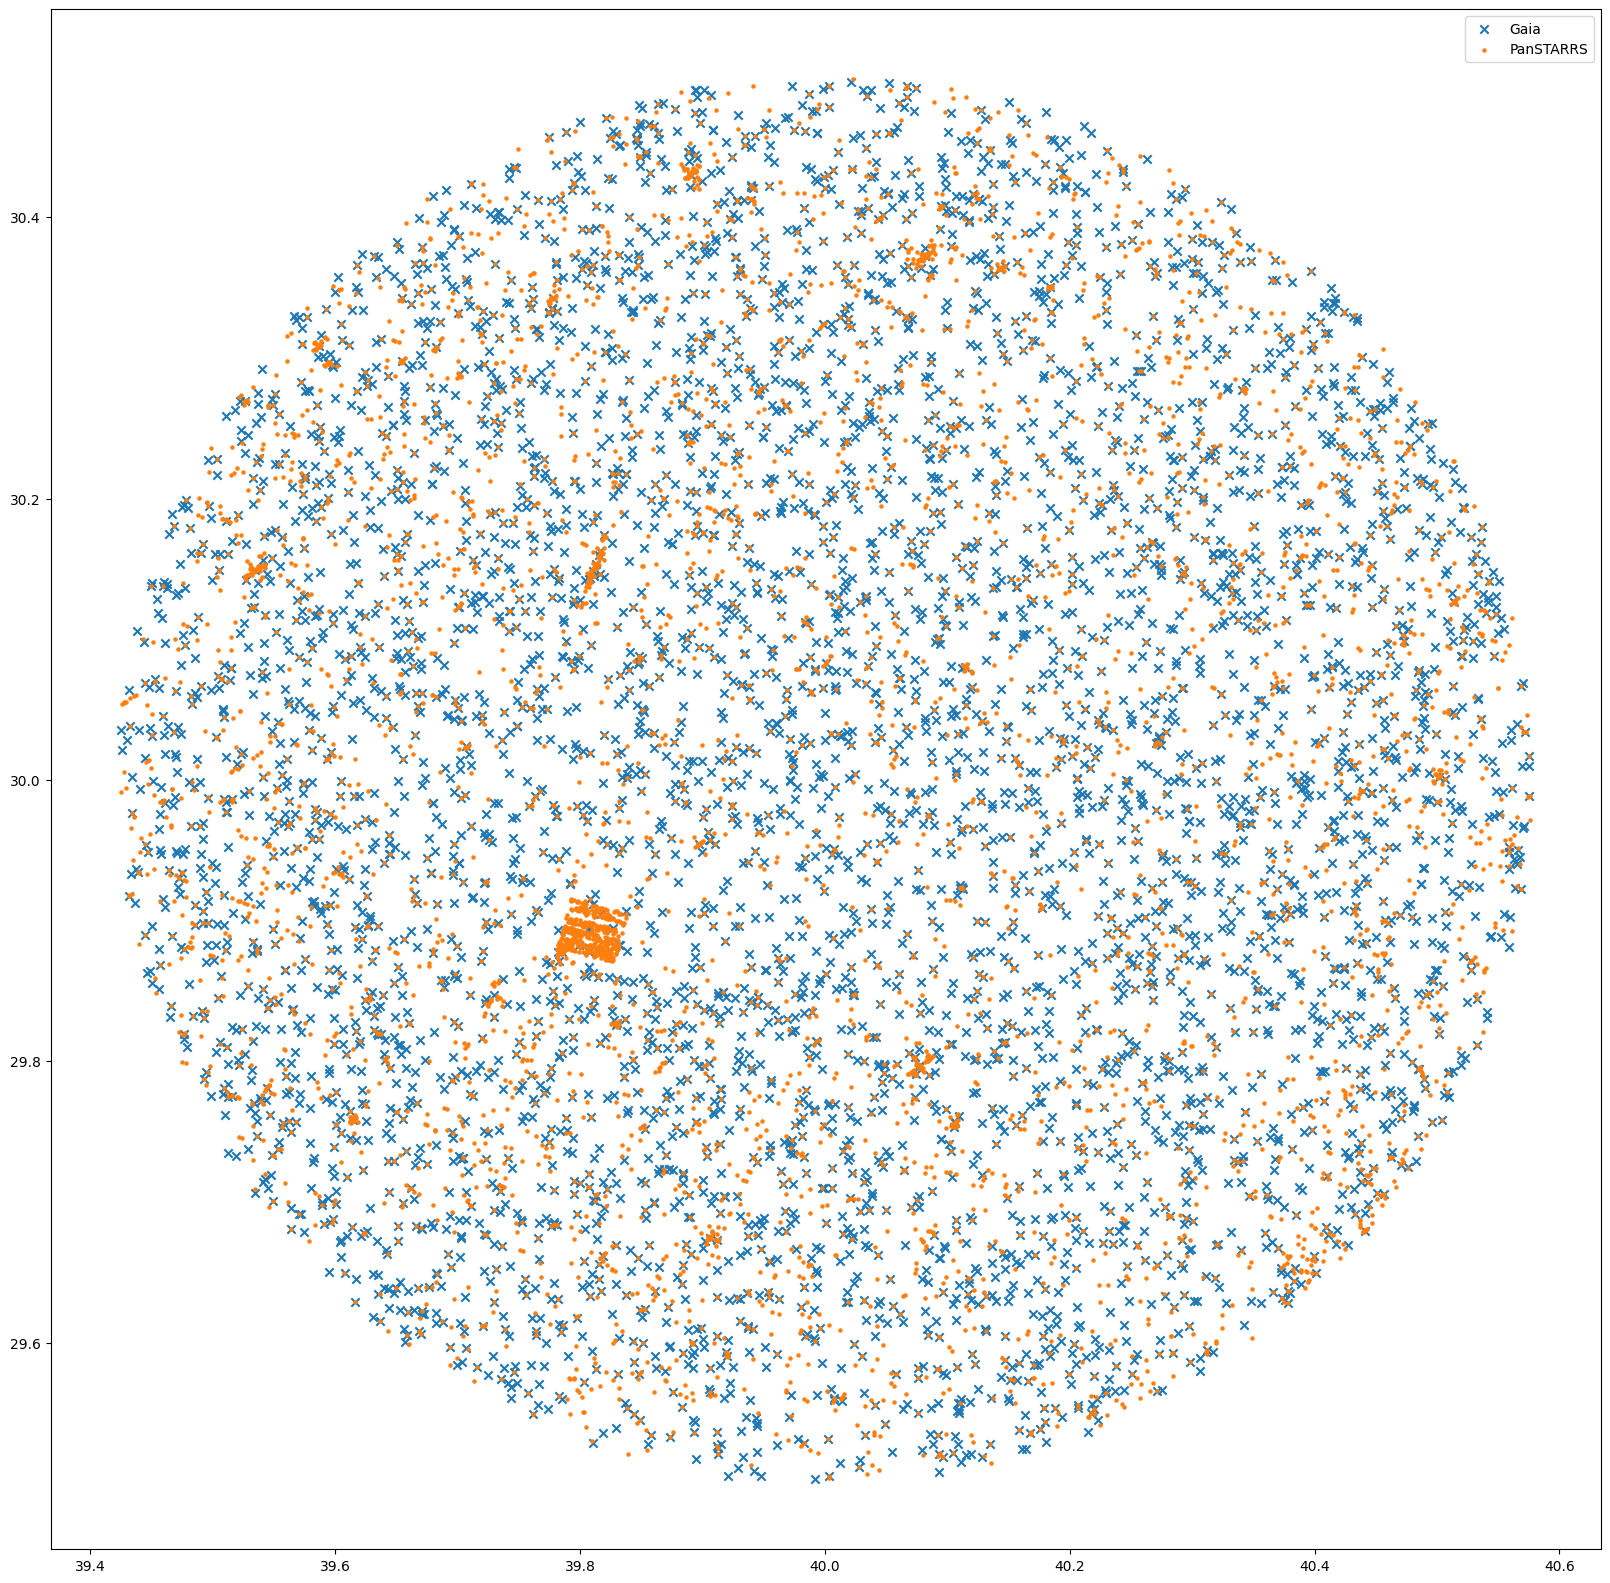

In [14]:
ps_good = panstarrs_cone_dat[(panstarrs_cone_dat['qualityFlag']<64) & ~((512 & panstarrs_cone_dat['objInfoFlag']).astype(bool)) & (panstarrs_cone_dat['nDetections']>1)]

plt.figure(figsize=(20,20))
plt.scatter(gaia_cone_dat['ra'],gaia_cone_dat['dec'],marker="x",label="Gaia")
plt.scatter(ps_good['raMean'],ps_good['decMean'],s=5,label="PanSTARRS")
plt.legend()
plt.show()

In [15]:
len(ps_good),len(gaia_cone_dat)

(5681, 5069)